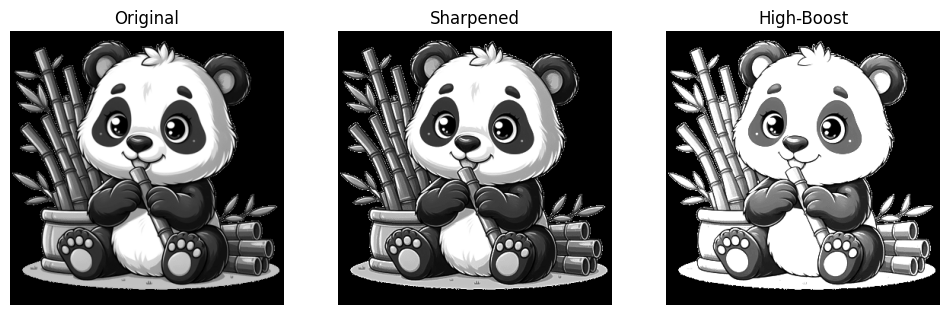

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image in grayscale
img = cv2.imread('/content/panda.png', cv2.IMREAD_GRAYSCALE)

# Blur the image
blurred = cv2.GaussianBlur(img, (5, 5), 0)

# Unsharp masking
mask = cv2.subtract(img, blurred)
sharpened = cv2.add(img, mask)

# High-boost filtering
A = 2.0  # Boost factor (>1)

high_boost = (A - 1) * img + sharpened

# Clip values to valid range
high_boost = np.clip(high_boost, 0, 255).astype(np.uint8)

# Display results
plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,3,2)
plt.imshow(sharpened, cmap='gray')
plt.title("Sharpened")
plt.axis('off')

plt.subplot(1,3,3)
plt.imshow(high_boost, cmap='gray')
plt.title("High-Boost")
plt.axis('off')

plt.show()

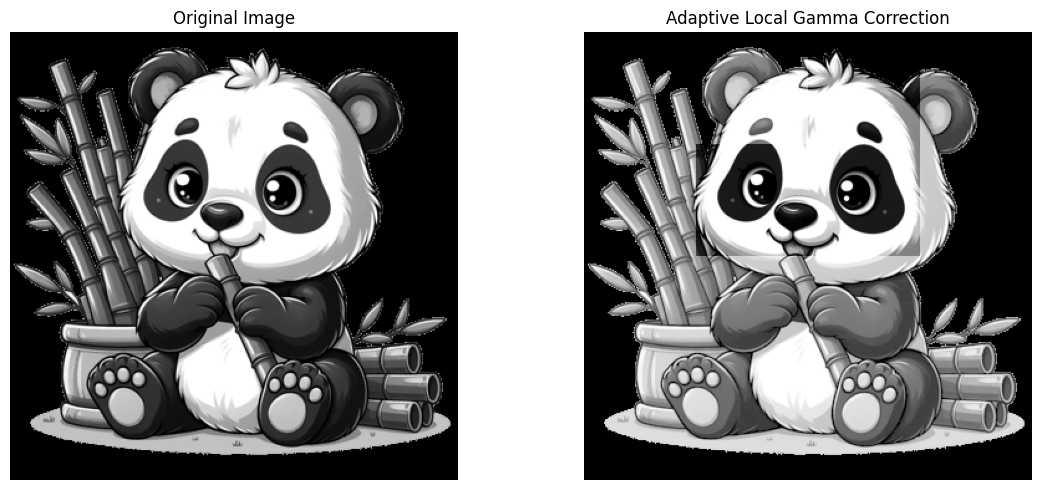

True

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
image = cv2.imread('/content/panda.png', cv2.IMREAD_GRAYSCALE)

# Check if image loaded
if image is None:
    raise FileNotFoundError("Image not found. Check file path.")

# Gamma values
gamma_dark = 0.5
gamma_bright = 1.5

# Threshold for dark and bright regions
threshold = 128

# Create output image
output = np.zeros_like(image, dtype=np.uint8)

# Get image dimensions
rows, cols = image.shape

# Divide image into 4×4 local regions
num_regions = 4

for i in range(num_regions):
    for j in range(num_regions):

        # Region boundaries
        r_start = i * rows // num_regions
        r_end = (i + 1) * rows // num_regions

        c_start = j * cols // num_regions
        c_end = (j + 1) * cols // num_regions

        # Extract region
        region = image[r_start:r_end, c_start:c_end]

        # Mean intensity
        mean_intensity = np.mean(region)

        # Select gamma adaptively
        if mean_intensity < threshold:
            gamma = gamma_dark
        else:
            gamma = gamma_bright

        # Normalize to [0,1]
        normalized = region.astype(np.float32) / 255.0

        # Apply gamma correction
        corrected = np.power(normalized, gamma)

        # Convert back to [0,255]
        corrected = np.clip(corrected * 255, 0, 255).astype(np.uint8)

        # Store corrected region
        output[r_start:r_end, c_start:c_end] = corrected

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(output, cmap='gray')
plt.title("Adaptive Local Gamma Correction")
plt.axis('off')

plt.tight_layout()
plt.show()

# Save output
cv2.imwrite("adaptive_local_gamma_output.jpg", output)